In [1]:
import numpy as np
import matplotlib.pyplot as plt
%pip install astroquery

Note: you may need to restart the kernel to use updated packages.


In [2]:
from astroquery.ipac.nexsci.nasa_exoplanet_archive import NasaExoplanetArchive

# Query planets with known period and semi-major axis from Planet Systems table
table = NasaExoplanetArchive.query_criteria(
    table="ps",
    select="pl_name, pl_orbper, pl_orbsmax, pl_rade, pl_bmassj",
    where="pl_orbper IS NOT NULL AND pl_orbsmax IS NOT NULL"
)
df = table.to_pandas()

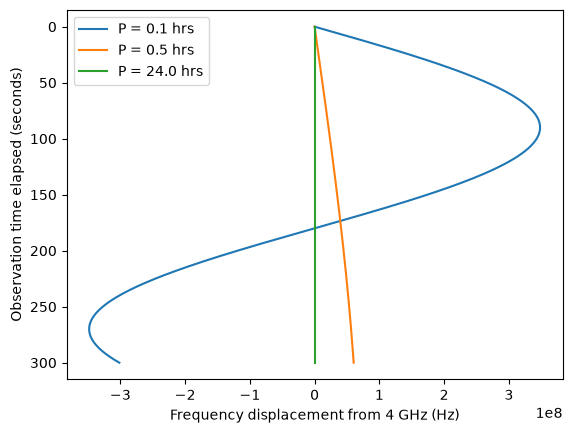

In [3]:
import numpy as np
import matplotlib.pyplot as plt

def plot_frequency_displacement(P_hours, a_AU, f0=4e9, T_obs=300):
    c = 3e8  # speed of light (m/s)
    P_sec = P_hours * 3600 # converting the period in hours to seconds
    a_m = a_AU * 1.496e11 # converting AU to meters
    
    v_orb = (2 * np.pi * a_m) / P_sec # orbital velocity
    t = np.linspace(0, T_obs, 500)
    
    # Frequency displacement over time
    v_rad = v_orb * np.sin(2 * np.pi * t / P_sec)
    delta_f = f0 * (v_rad - v_rad[0]) / c
    
    return t, delta_f
periods_to_test = [0.1, 0.5, 24.0]  # in hours
for P in periods_to_test:
    t, df = plot_frequency_displacement(P_hours=P, a_AU=0.01)
    plt.plot(df, t, label=f'P = {P} hrs')

plt.gca().invert_yaxis()
plt.xlabel('Frequency displacement from 4 GHz (Hz)')
plt.ylabel('Observation time elapsed (seconds)')
plt.legend()
plt.show()

In [4]:
def evaluate_curvature(P_hours, a_AU, f0=4e9, T_obs=300):
    c = 3e8
    P_sec = P_hours * 3600
    a_m = a_AU * 1.496e11
    
    v_orb = (2 * np.pi * a_m) / P_sec
    t = np.linspace(0, T_obs, 500)
    
    v_rad = v_orb * np.sin(2 * np.pi * t / P_sec)
    delta_f = f0 * (v_rad - v_rad[0]) / c
    
    # Linear fit to the generated delta_f curve
    p_fit = np.polyfit(t, delta_f, deg=1)
    linear_trend = np.polyval(p_fit, t)
    
    rmse = np.sqrt(np.mean((delta_f - linear_trend)**2)) # calculates the root mean square error
    
    return t, delta_f, rmse

# Get exoplanet data
table = NasaExoplanetArchive.query_criteria(
    table="ps",
    select="pl_name, pl_orbper, pl_orbsmax",
    where="pl_orbper IS NOT NULL AND pl_orbsmax IS NOT NULL AND default_flag=1"
)
df = table.to_pandas()
df['pl_orbper_hr'] = df['pl_orbper'] * 24.0

# Calculate RMSE for each planet
df['rmse_hz'] = [
    evaluate_curvature(row['pl_orbper_hr'], row['pl_orbsmax'])[2]
    for _, row in df.iterrows()
]

# Find planets where curvature becomes significant (RMSE > 5 Hz)
curved_planets = df[df['rmse_hz'] > 5].sort_values('pl_orbper_hr')
print("Shortest-period planets exhibiting significant curvature:")
print(curved_planets[['pl_name', 'pl_orbper_hr', 'pl_orbsmax', 'rmse_hz']].head(20))
print("Total planets with high curvature:", len(curved_planets))

Shortest-period planets exhibiting significant curvature:
               pl_name  pl_orbper_hr  pl_orbsmax      rmse_hz
1833  PSR J1719-1438 b      2.176951    0.004400  1851.091183
793         TOI-2431 b      5.380699    0.006300    71.228657
1416          KOI-55 b      5.762496    0.006000    51.571549
683           K2-141 b      6.727786    0.007470    34.561497
2533        TOI-4552 b      7.226408    0.005626    19.554804
1097  PSR J2322-2650 b      7.751136    0.010200    26.787943
2928          KOI-55 c      8.229288    0.007600    15.710101
625         TOI-2260 b      8.459347    0.009700    17.957447
1740       Kepler-78 b      8.520179    0.009010    16.208831
1800          K2-157 b      8.766180    0.009620    15.444038
2072          K2-131 b      8.863291    0.009360    14.378885
626         TOI-2445 b      8.907074    0.006400     9.639844
3394       TOI-4527.01      9.586668    0.008332     9.352763
869         TOI-1442 b      9.817625    0.007100     7.245684
1976       K

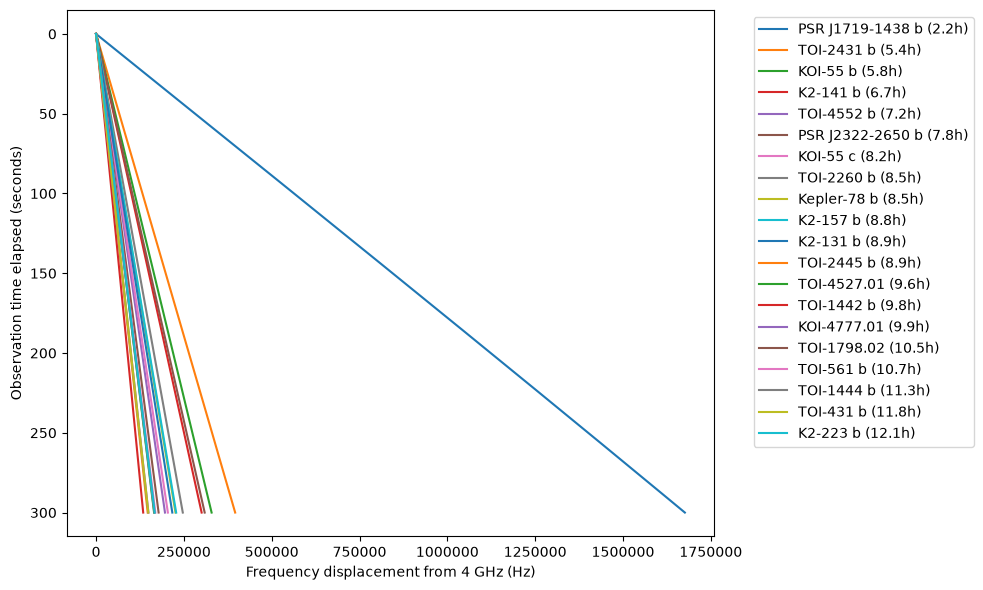

In [5]:
plt.figure(figsize=(10, 6))

# Loop through each planet in the curved_planets DataFrame
for _, row in curved_planets.iterrows():
    name = row['pl_name']
    p_hr = row['pl_orbper_hr']
    a_au = row['pl_orbsmax']
    
    # Calculate displacement using real P and real a
    t, df_vals = evaluate_curvature(p_hr, a_au)[:2]
    
    plt.plot(df_vals, t, label=f"{name} ({p_hr:.1f}h)")

plt.gca().invert_yaxis()
plt.ticklabel_format(style='plain', useOffset=False)  # Prevents 1e8 scientific notation offset
plt.xlabel('Frequency displacement from 4 GHz (Hz)')
plt.ylabel('Observation time elapsed (seconds)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')  # Places legend outside plot so it doesn't cover curves
plt.tight_layout()
plt.show()

In [6]:
import pandas as pd

# Hardcoded catalog of well-studied super-fast rotator asteroids
fast_rotators = [
    {'name': '2008 DP4',     'rot_per_hr': 0.1,    'radius_m': 30.0},  # ~6 minute period
    {'name': '2014 RC',       'rot_per_hr': 0.042,  'radius_m': 11.0},  # ~2.5 minute period
    {'name': '2015 VY105',   'rot_per_hr': 0.018,  'radius_m': 5.0},   # ~1.1 minute period
    {'name': '2011 PT',       'rot_per_hr': 0.16,   'radius_m': 18.0},  # ~9.6 minute period
    {'name': '2017 WF13',     'rot_per_hr': 0.08,   'radius_m': 20.0},  # ~4.8 minute period
    {'name': '2000 DO8',     'rot_per_hr': 0.022,  'radius_m': 40.0},  # ~1.3 minute period
]

df_asteroids = pd.DataFrame(fast_rotators)
print(f"Successfully created df_asteroids with {len(df_asteroids)} objects!")

Successfully created df_asteroids with 6 objects!


In [7]:
def evaluate_curvature_asteroid(P_hours, radius_m, f0=4e9, T_obs=300):
    c = 3e8
    P_sec = P_hours * 3600.0
    
    # Angular velocity (rad/s) and tangential rotation velocity (m/s)
    omega = (2 * np.pi) / P_sec
    v_rot = omega * radius_m
    
    t = np.linspace(0, T_obs, 500)
    
    # Line-of-sight velocity curve
    v_rad = v_rot * np.sin(omega * t)
    delta_f = f0 * (v_rad - v_rad[0]) / c
    
    # Measure deviation from linear fit
    p_fit = np.polyfit(t, delta_f, deg=1)
    linear_trend = np.polyval(p_fit, t)
    rmse = np.sqrt(np.mean((delta_f - linear_trend)**2))
    
    return t, delta_f, rmse

         name  rot_per_hr  radius_m    rmse_hz
2  2015 VY105       0.018       5.0   4.511951
5    2000 DO8       0.022      40.0  29.748574
1     2014 RC       0.042      11.0   3.975405
4   2017 WF13       0.080      20.0   2.808777
0    2008 DP4       0.100      30.0   2.848158
3     2011 PT       0.160      18.0   0.862010


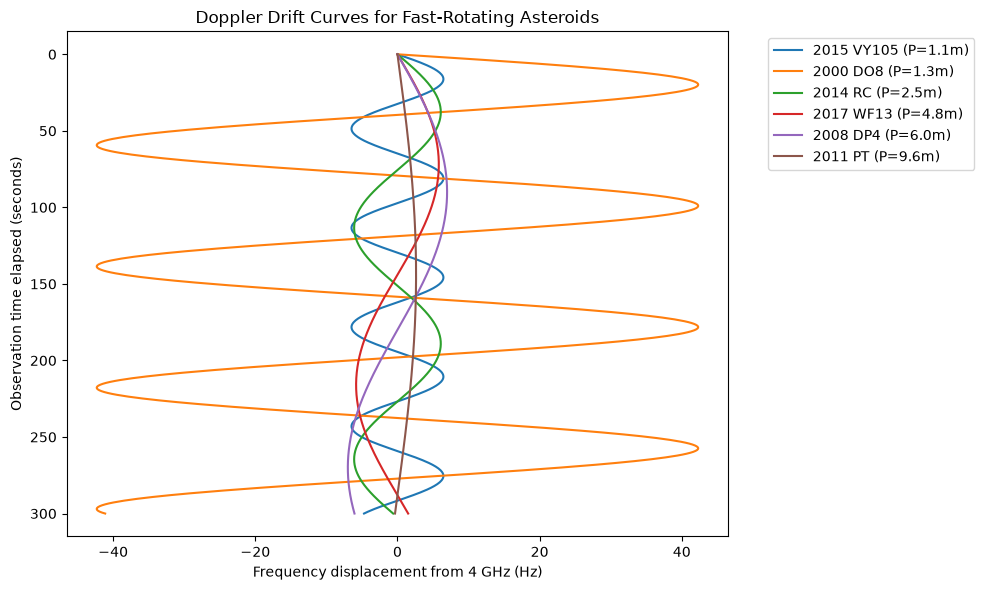

In [8]:
# Calculate RMSE for each asteroid
df_asteroids['rmse_hz'] = [
    evaluate_curvature_asteroid(row['rot_per_hr'], row['radius_m'])[2]
    for _, row in df_asteroids.iterrows()
]

# Sort by rotation period (shortest first)
curved_asteroids = df_asteroids.sort_values('rot_per_hr')
print(curved_asteroids.head(10))

# Plot the top fast rotators
plt.figure(figsize=(10, 6))

for _, row in curved_asteroids.head(10).iterrows():
    t, delta_f, _ = evaluate_curvature_asteroid(row['rot_per_hr'], row['radius_m'])
    plt.plot(delta_f, t, label=f"{row['name']} (P={row['rot_per_hr']*60:.1f}m)")

plt.gca().invert_yaxis()
plt.ticklabel_format(style='plain', useOffset=False)
plt.xlabel('Frequency displacement from 4 GHz (Hz)')
plt.ylabel('Observation time elapsed (seconds)')
plt.title('Doppler Drift Curves for Fast-Rotating Asteroids')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()